In [1]:
# Instala a biblioteca do Kaggle
!pip install -q kaggle

# Importa as bibliotecas necessárias
import os
from google.colab import files

# Nome do dataset no Kaggle
dataset_path = "expeditojunior/enade20082018"

# Cria uma pasta para os dados e realiza o download
print("Baixando o dataset do Kaggle...")
!kaggle datasets download -d {dataset_path} -p ./dados_enade --unzip

# Lista os arquivos baixados
print("Arquivos baixados:")
os.listdir('./dados_enade')

Baixando o dataset do Kaggle...
Dataset URL: https://www.kaggle.com/datasets/expeditojunior/enade20082018
License(s): CC0-1.0
100% 42.1M/42.1M [00:00<00:00, 103MB/s]

Arquivos baixados:


['enade_2008_2018.rds']

In [2]:
# Garante que o rpy2 está instalado (geralmente já vem por padrão no Colab)
#!pip install -q rpy2

# Importa as bibliotecas necessárias para conversão R-Python
import pandas as pd
import rpy2.robjects as robjects
from rpy2.robjects import pandas2ri

# Ativa a conversão automática de objetos R para Pandas
pandas2ri.activate()

# Caminho para o arquivo baixado
caminho_arquivo = './dados_enade/enade_2008_2018.rds'

# Carrega os dados utilizando o motor nativo do R
print("Carregando os dados via rpy2 (R)...")
readRDS = robjects.r['readRDS']
df_r = readRDS(caminho_arquivo)

# Converte o objeto do R em um DataFrame do Pandas
df = pandas2ri.rpy2py(df_r)

# Exibe as dimensões do dataset
print(f"\nDimensões do dataset: {df.shape[0]} linhas e {df.shape[1]} colunas\n")

# Exibe as primeiras 5 linhas
print("--- Primeiras 5 linhas do DataFrame ---")
display(df.head())

# Exibe informações gerais sobre as colunas e tipos de dados
print("\n--- Informações estruturais dos dados ---")
df.info()

# Exibe estatísticas descritivas rápidas do dataset
print("\n--- Resumo estatístico descritivo ---")
display(df.describe(include='all'))

Carregando os dados via rpy2 (R)...

Dimensões do dataset: 3712412 linhas e 20 colunas

--- Primeiras 5 linhas do DataFrame ---


,NU_ANO,NU_IDADE,TP_SEXO,ANO_FIM_EM,ANO_IN_GRAD,QE_I13,QE_I14,NT_FG,NT_CE,NT_GER,MUNICIPIO,UF,LONG,LAT,ALT,CATEGAD,GRUPO,ORGANIZACAO,REGIAO_CURSO,CURSO
1,1,21,1,2005,0,3,3,7.5,18.900000,16.100000,CUIABÁ,11,-56.073252,-15.569989,242.927031,Publica Federal,MATEMATICA,Universidade,CENTRO-OESTE,MATEMÁTICA
2,1,23,2,2000,2003,3,3,7.5,22.000000,18.400000,CUIABÁ,11,-56.073252,-15.569989,242.927031,Publica Federal,MATEMATICA,Universidade,CENTRO-OESTE,MATEMÁTICA
3,1,33,2,2000,2002,7,8,22.5,9.400000,12.700000,CUIABÁ,11,-56.073252,-15.569989,242.927031,Publica Federal,MATEMATICA,Universidade,CENTRO-OESTE,MATEMÁTICA
4,1,36,2,1995,1996,3,3,31.5,12.600000,17.299999,CUIABÁ,11,-56.073252,-15.569989,242.927031,Publica Federal,MATEMATICA,Universidade,CENTRO-OESTE,MATEMÁTICA
7,1,45,2,1995,2001,3,3,54.0,34.599998,39.500000,CUIABÁ,11,-56.073252,-15.569989,242.927031,Publica Federal,MATEMATICA,Universidade,CENTRO-OESTE,MATEMÁTICA



--- Informações estruturais dos dados ---
<class 'pandas.core.frame.DataFrame'>
Index: 3712412 entries, 1 to 5481215
Data columns (total 20 columns):
 #   Column        Dtype  
---  ------        -----  
 0   NU_ANO        int64  
 1   NU_IDADE      int64  
 2   TP_SEXO       int64  
 3   ANO_FIM_EM    int64  
 4   ANO_IN_GRAD   int64  
 5   QE_I13        int64  
 6   QE_I14        int64  
 7   NT_FG         float64
 8   NT_CE         float64
 9   NT_GER        float64
 10  MUNICIPIO     object 
 11  UF            int64  
 12  LONG          float64
 13  LAT           float64
 14  ALT           float64
 15  CATEGAD       object 
 16  GRUPO         object 
 17  ORGANIZACAO   object 
 18  REGIAO_CURSO  object 
 19  CURSO         object 
dtypes: float64(6), int64(8), object(6)
memory usage: 594.8+ MB

--- Resumo estatístico descritivo ---


,NU_ANO,NU_IDADE,TP_SEXO,ANO_FIM_EM,ANO_IN_GRAD,QE_I13,QE_I14,NT_FG,NT_CE,NT_GER,MUNICIPIO,UF,LONG,LAT,ALT,CATEGAD,GRUPO,ORGANIZACAO,REGIAO_CURSO,CURSO
count,3.712412e+06,3.712412e+06,3.712412e+06,3.712412e+06,3.712412e+06,3.712412e+06,3.712412e+06,3.712412e+06,3.712412e+06,3.712412e+06,3712412,3.712412e+06,3.712412e+06,3.712412e+06,3.712412e+06,3712412,3712412,3712412,3712412,3553049
unique,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1231,NaN,NaN,NaN,NaN,18,158,10,5,593
top,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,SÃO PAULO,NaN,NaN,NaN,NaN,Privada sem fins lucrativos,ADMINISTRACAO,Universidade,SUDESTE,ADMINISTRAÇÃO
freq,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,340977,NaN,NaN,NaN,NaN,1666587,465454,1955328,1697060,425055
mean,5.425836e+00,2.793214e+01,1.401635e+00,2.004377e+03,1.697268e+03,5.871039e+00,5.714428e+00,4.841459e+01,4.055240e+01,4.252016e+01,NaN,1.731890e+01,-4.653327e+01,-1.910376e+01,4.482892e+02,NaN,NaN,NaN,NaN,NaN
std,3.108594e+00,8.110045e+00,4.902843e-01,6.991045e+00,7.288848e+02,1.814046e+00,1.706676e+00,1.885922e+01,1.669228e+01,1.514260e+01,NaN,6.852124e+00,5.552027e+00,7.539814e+00,3.656009e+02,NaN,NaN,NaN,NaN,NaN
min,1.000000e+00,0.000000e+00,1.000000e+00,1.000000e+03,0.000000e+00,1.000000e+00,1.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,NaN,1.000000e+00,-7.267253e+01,-3.351986e+01,0.000000e+00,NaN,NaN,NaN,NaN,NaN
25%,2.000000e+00,2.200000e+01,1.000000e+00,2.001000e+03,2.005000e+03,5.000000e+00,5.000000e+00,3.460000e+01,2.830000e+01,3.170000e+01,NaN,1.300000e+01,-4.927185e+01,-2.356739e+01,2.990852e+01,NaN,NaN,NaN,NaN,NaN
50%,6.000000e+00,2.500000e+01,1.000000e+00,2.006000e+03,2.010000e+03,5.000000e+00,5.000000e+00,4.930000e+01,3.970000e+01,4.200000e+01,NaN,1.800000e+01,-4.657038e+01,-2.229579e+01,5.402315e+02,NaN,NaN,NaN,NaN,NaN
75%,8.000000e+00,3.100000e+01,2.000000e+00,2.009000e+03,2.013000e+03,7.000000e+00,6.000000e+00,6.200000e+01,5.220000e+01,5.300000e+01,NaN,2.500000e+01,-4.322788e+01,-1.556999e+01,7.836151e+02,NaN,NaN,NaN,NaN,NaN


📌 Estrutura Geral
Tamanho do Dataset: O conjunto de dados é muito grande, contendo 3.712.412 linhas (registros de estudantes) e 20 colunas. Com dados do Enade de 2008 a 2018



👥 Perfil dos Estudantes
Idade (NU_IDADE): A média de idade dos candidatos ao realizar o ENADE é de aproximadamente 27,9 anos. No entanto, a mediana (50%) é de 25 anos, indicando que metade dos participantes tem 25 anos ou menos. O desvio padrão é de 8,1 anos.
Curso mais frequente: O curso de Administração é o mais populoso dentro deste recorte histórico, totalizando mais de 425 mil registros.
Região com mais cursos: A região Sudeste concentra a maior quantidade de registros de cursos realizados (cerca de 1,69 milhão).

📊 Desempenho nas Notas
Nota Geral (NT_GER): A nota geral média dos estudantes participantes é de 42,52 pontos (de uma escala de 0 a 100), com um desvio padrão de 15,14 pontos.
Componente Específico (NT_CE): Obteve média de 40,55 pontos.
Formação Geral (NT_FG): Teve a maior média geral dos componentes, registrando 48,41 pontos.

In [3]:
# Calcula o menor e o maior valor da coluna NU_ANO
menor_ano = df['NU_ANO'].min()
maior_ano = df['NU_ANO'].max()

# Exibe os resultados obtidos com pequenos comentários
print(f"O menor valor registrado em NU_ANO é: {menor_ano}")
print(f"O maior valor registrado em NU_ANO é: {maior_ano}")

O menor valor registrado em NU_ANO é: 1
O maior valor registrado em NU_ANO é: 10


Neste dataset, esses valores numéricos de 1 a 10 representam codificações para os anos correspondentes à série histórica do ENADE, abrangendo o período de 2008 a 2018.

In [6]:
# Exibe todos os valores únicos da coluna CATEGAD
valores_unicos_categad = df['CATEGAD'].unique()
print(valores_unicos_categad)

['Publica Federal' 'Publica Estadual' 'Privada sem fins lucrativos'
 'Publica Municipal' 'Pessoa Juridica de Direito Publico - Federal'
 'Pessoa Juridica de Direito Publico - Estadual'
 'Pessoa Juridica de Direito Privado - Sem fins lucrativos - Sociedade                                                                                   '
 'Pessoa Juridica de Direito Privado - Sem fins lucrativos - Associacao de Utilidade Publica'
 'Pessoa Juridica de Direito Publico - Municipal'
 'Privada com fins lucrativos'
 'Pessoa Juridica de Direito Privado - Com fins lucrativos - Sociedade Mercantil ou Comercial'
 'Nao disponivel'
 'Pessoa Juridica de Direito Privado - Com fins lucrativos - Associaco de Utilidade Publica'
 'Pessoa Juridica de Direito Publico - Federal '
 'Pessoa Juridica de Direito Privado - Sem fins lucrativos - Fundacao'
 'Pessoa Juridica de Direito Privado - Com fins lucrativos - Sociedade Civil'
 'Especial' 'Fundacao Publica de Direito Privado Municipal']


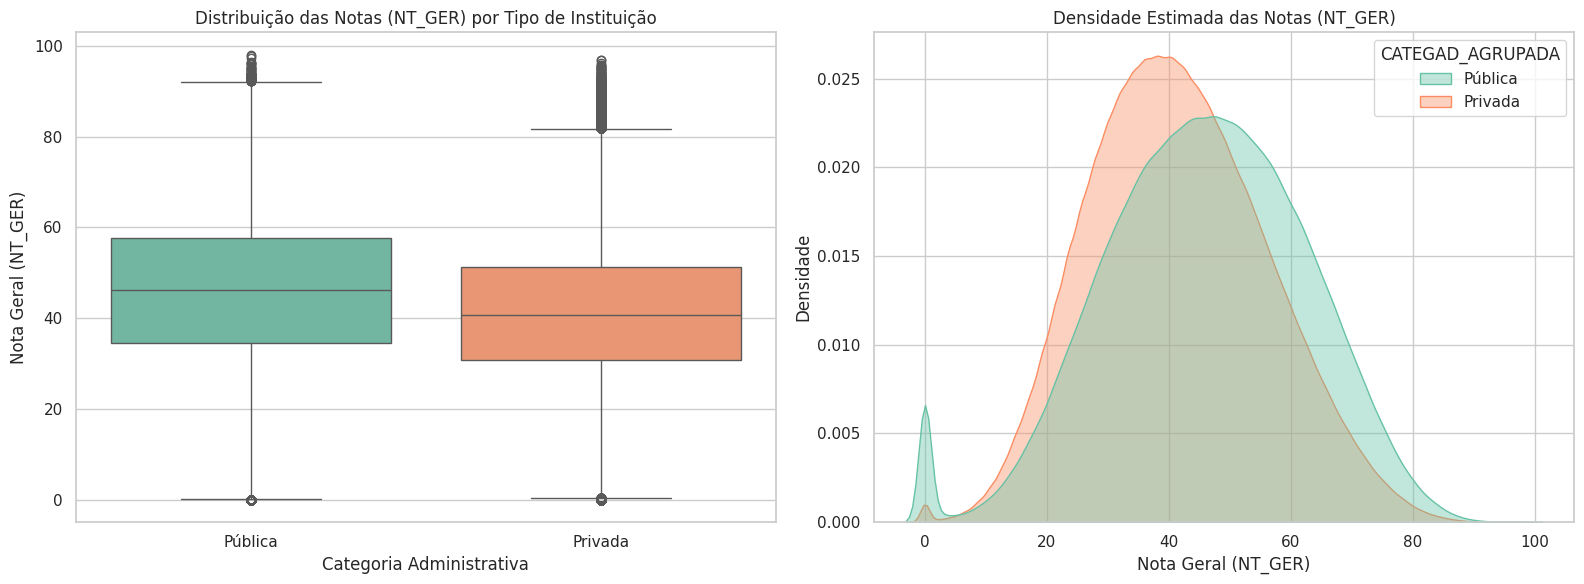

In [7]:
# Importa as bibliotecas para visualização gráfica
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Remove linhas com valores nulos nas colunas de interesse
df_plot = df.dropna(subset=['NT_GER', 'CATEGAD']).copy()

# Garante a remoção das categorias solicitadas
categorias_remover = [
    'Especial',
    'Nao disponivel',
    'Não disponível',
    'Fundacao Publica de Direito Privado Municipal',
    'Fundacao Publica de Direito Privado Municipal'
]
df_plot = df_plot[~df_plot['CATEGAD'].isin(categorias_remover)]

# Define a função de mapeamento simplificado para Pública e Privada
def mapear_tipo_simples(cat):
    cat_lower = str(cat).lower()
    if 'publica' in cat_lower or 'público' in cat_lower or 'federal' in cat_lower or 'estadual' in cat_lower or 'municipal' in cat_lower:
        return 'Pública'
    else:
        return 'Privada'

# Aplica o mapeamento
df_plot['CATEGAD_AGRUPADA'] = df_plot['CATEGAD'].apply(mapear_tipo_simples)

# Define o estilo visual dos gráficos
sns.set_theme(style="whitegrid")

# Cria uma figura com dois subplots para uma análise mais completa
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Gráfico 1: Boxplot para comparar a distribuição e medianas das notas
sns.boxplot(
    data=df_plot,
    x='CATEGAD_AGRUPADA',
    y='NT_GER',
    hue='CATEGAD_AGRUPADA',
    ax=axes[0],
    palette='Set2',
    legend=False
)
axes[0].set_title('Distribuição das Notas (NT_GER) por Tipo de Instituição')
axes[0].set_xlabel('Categoria Administrativa')
axes[0].set_ylabel('Nota Geral (NT_GER)')

# Gráfico 2: KDE Plot (Densidade) para visualizar a concentração das notas
sns.kdeplot(
    data=df_plot,
    x='NT_GER',
    hue='CATEGAD_AGRUPADA',
    common_norm=False,
    fill=True,
    alpha=0.4,
    ax=axes[1],
    palette='Set2'
)
axes[1].set_title('Densidade Estimada das Notas (NT_GER)')
axes[1].set_xlabel('Nota Geral (NT_GER)')
axes[1].set_ylabel('Densidade')

# Ajusta o layout para evitar sobreposições e exibe o gráfico
plt.tight_layout()
plt.show()

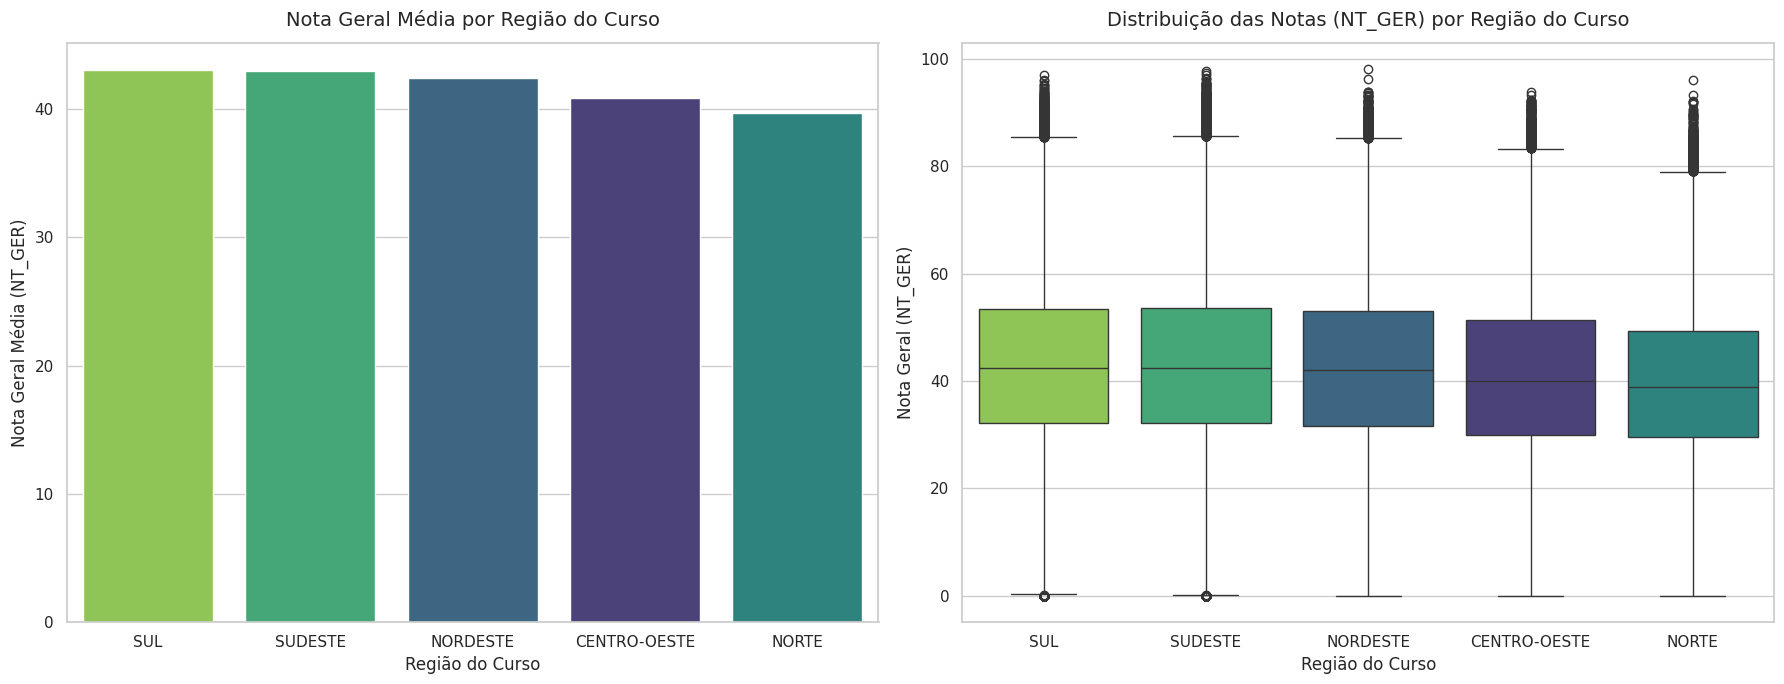

In [10]:
# Importa as bibliotecas necessárias para plotagem
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Remove valores nulos nas colunas de análise para garantir a consistência
df_regiao = df.dropna(subset=['NT_GER', 'REGIAO_CURSO']).copy()

# Calcula a média de notas por região para ordenar o gráfico de barras
ordem_regioes = df_regiao.groupby('REGIAO_CURSO')['NT_GER'].mean().sort_values(ascending=False).index

# Configura o tema do Seaborn
sns.set_theme(style="whitegrid")

# Cria uma figura com dois subplots
fig, axes = plt.subplots(1, 2, figsize=(18, 7))

# Gráfico 1: Barras com a Nota Média Geral por Região
sns.barplot(
    data=df_regiao,
    x='REGIAO_CURSO',
    y='NT_GER',
    order=ordem_regioes,
    hue='REGIAO_CURSO',
    ax=axes[0],
    palette='viridis',
    errorbar=None,
    legend=False
)
axes[0].set_title('Nota Geral Média por Região do Curso', fontsize=14, pad=12)
axes[0].set_xlabel('Região do Curso', fontsize=12)
axes[0].set_ylabel('Nota Geral Média (NT_GER)', fontsize=12)

# Gráfico 2: Boxplot com a Distribuição das Notas por Região
sns.boxplot(
    data=df_regiao,
    x='REGIAO_CURSO',
    y='NT_GER',
    order=ordem_regioes,
    hue='REGIAO_CURSO',
    ax=axes[1],
    palette='viridis',
    legend=False
)
axes[1].set_title('Distribuição das Notas (NT_GER) por Região do Curso', fontsize=14, pad=12)
axes[1].set_xlabel('Região do Curso', fontsize=12)
axes[1].set_ylabel('Nota Geral (NT_GER)', fontsize=12)

# Ajusta o layout para evitar sobreposição
plt.tight_layout()
plt.show()

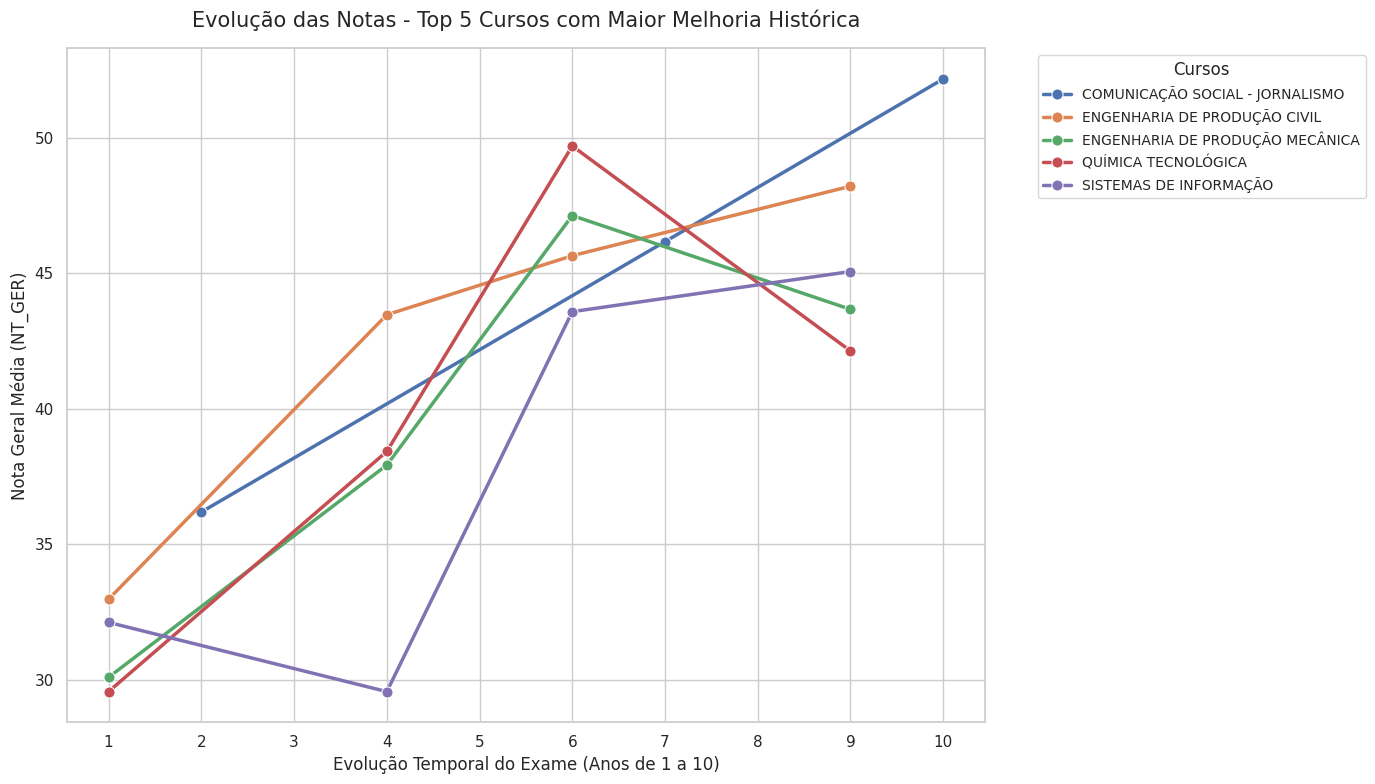

In [8]:
# Importa as bibliotecas necessárias para análise e visualização
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Remove dados nulos importantes para a análise temporal
df_temp = df.dropna(subset=['NT_GER', 'CURSO', 'NU_ANO']).copy()

# Agrupa os dados por curso e ano do exame para calcular a média de cada ano
evolucao_cursos = df_temp.groupby(['CURSO', 'NU_ANO']).agg(
    nota_media=('NT_GER', 'mean'),
    qtd_alunos=('NT_GER', 'count')
).reset_index()

# Filtra para manter apenas cursos que possuam consistência de dados (pelo menos 100 alunos por ano avaliado)
cursos_consistentes = evolucao_cursos.groupby('CURSO').filter(lambda x: (x['qtd_alunos'] > 100).all() and len(x) >= 2)

# Para descobrir quem mais melhorou, calculamos a diferença entre o último ano e o primeiro ano registrado de cada curso
melhoria = []
for curso, dados in cursos_consistentes.groupby('CURSO'):
    dados_ordenados = dados.sort_values('NU_ANO')
    primeira_nota = dados_ordenados.iloc[0]['nota_media']
    ultima_nota = dados_ordenados.iloc[-1]['nota_media']
    ganho = ultima_nota - primeira_nota
    melhoria.append({'CURSO': curso, 'ganho': ganho})

df_melhoria = pd.DataFrame(melhoria)

# Seleciona as 5 maiores evoluções (maiores ganhos)
top_5_melhoria = df_melhoria.nlargest(5, 'ganho')['CURSO'].tolist()

# Filtra os dados de evolução temporal apenas para estes 5 cursos destacados
df_grafico = cursos_consistentes[cursos_consistentes['CURSO'].isin(top_5_melhoria)].copy()

# Inicia a plotagem do gráfico de evolução
plt.figure(figsize=(14, 8))
sns.set_theme(style="whitegrid")

# Cria o gráfico de linhas para representar a evolução temporal
sns.lineplot(
    data=df_grafico,
    x='NU_ANO',
    y='nota_media',
    hue='CURSO',
    marker='o',
    linewidth=2.5,
    markersize=8
)

# Configura títulos, legendas e eixos do gráfico
plt.title('Evolução das Notas - Top 5 Cursos com Maior Melhoria Histórica', fontsize=15, pad=15)
plt.xlabel('Evolução Temporal do Exame (Anos de 1 a 10)', fontsize=12)
plt.ylabel('Nota Geral Média (NT_GER)', fontsize=12)
plt.xticks(range(1, 11))  # Garante os intervalos de 1 a 10 no eixo X
plt.legend(title='Cursos', bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=10)

# Exibe o gráfico estruturado
plt.tight_layout()
plt.show()

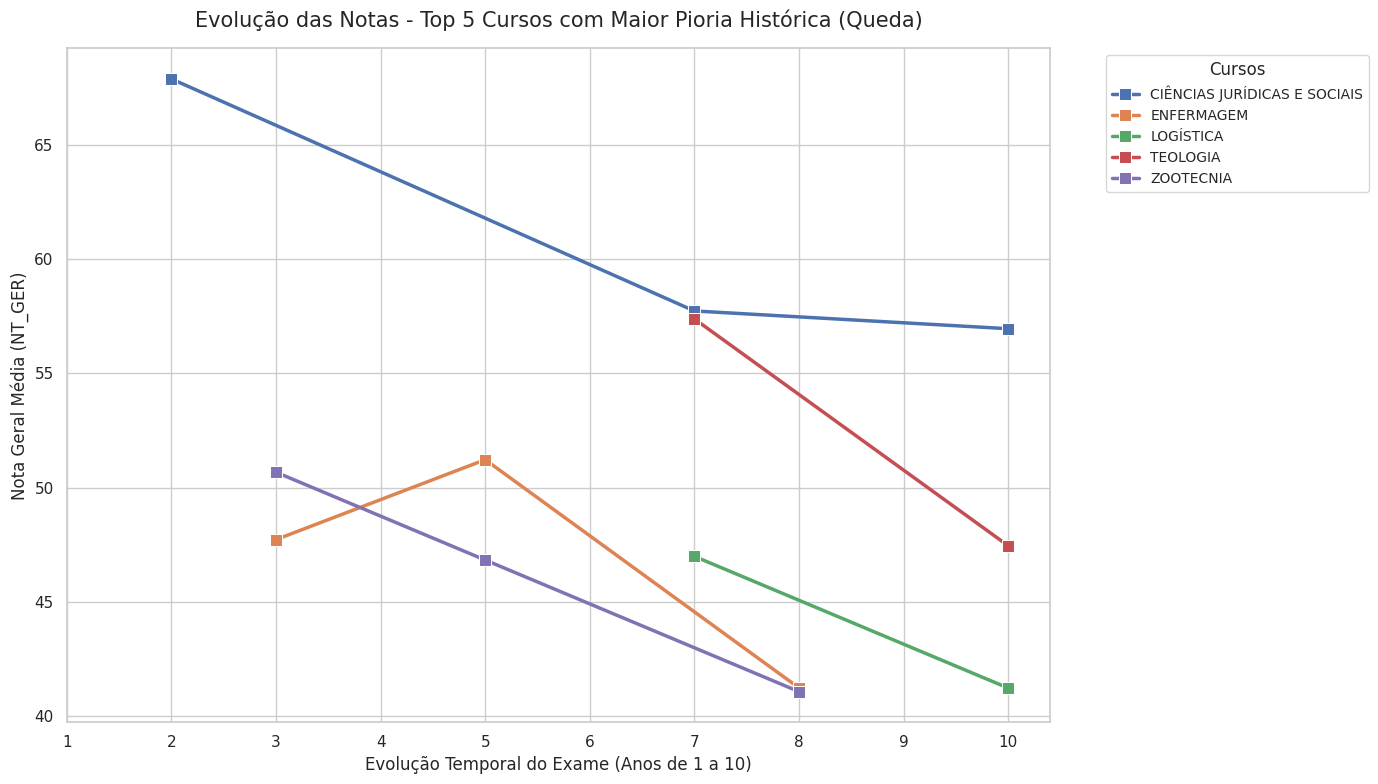

In [9]:
# Importa as bibliotecas necessárias para análise e visualização
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Remove dados nulos importantes para a análise temporal
df_temp = df.dropna(subset=['NT_GER', 'CURSO', 'NU_ANO']).copy()

# Agrupa os dados por curso e ano do exame para calcular a média de cada ano
evolucao_cursos = df_temp.groupby(['CURSO', 'NU_ANO']).agg(
    nota_media=('NT_GER', 'mean'),
    qtd_alunos=('NT_GER', 'count')
).reset_index()

# Filtra para manter apenas cursos estáveis e consistentes (pelo menos 100 alunos por ano avaliado)
cursos_consistentes = evolucao_cursos.groupby('CURSO').filter(lambda x: (x['qtd_alunos'] > 100).all() and len(x) >= 2)

# Calcula a diferença entre o último ano e o primeiro ano registrado de cada curso
melhoria = []
for curso, dados in cursos_consistentes.groupby('CURSO'):
    dados_ordenados = dados.sort_values('NU_ANO')
    primeira_nota = dados_ordenados.iloc[0]['nota_media']
    ultima_nota = dados_ordenados.iloc[-1]['nota_media']
    ganho = ultima_nota - primeira_nota
    melhoria.append({'CURSO': curso, 'ganho': ganho})

df_melhoria = pd.DataFrame(melhoria)

# Seleciona as 5 maiores quedas (os menores valores de ganho/valores mais negativos)
top_5_pioria = df_melhoria.nsmallest(5, 'ganho')['CURSO'].tolist()

# Filtra os dados de evolução temporal apenas para estes 5 cursos que mais decresceram
df_grafico_pioria = cursos_consistentes[cursos_consistentes['CURSO'].isin(top_5_pioria)].copy()

# Inicia a plotagem do gráfico de evolução descendente
plt.figure(figsize=(14, 8))
sns.set_theme(style="whitegrid")

# Cria o gráfico de linhas para representar a evolução temporal
sns.lineplot(
    data=df_grafico_pioria,
    x='NU_ANO',
    y='nota_media',
    hue='CURSO',
    marker='s',  # Marcador quadrado diferenciado
    linewidth=2.5,
    markersize=8
)

# Configura títulos, legendas e eixos do gráfico
plt.title('Evolução das Notas - Top 5 Cursos com Maior Pioria Histórica (Queda)', fontsize=15, pad=15)
plt.xlabel('Evolução Temporal do Exame (Anos de 1 a 10)', fontsize=12)
plt.ylabel('Nota Geral Média (NT_GER)', fontsize=12)
plt.xticks(range(1, 11))  # Garante os intervalos de 1 a 10 no eixo X
plt.legend(title='Cursos', bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=10)

# Exibe o gráfico estruturado
plt.tight_layout()
plt.show()